## Домашка 3

#### *«Ты понимаешь, что это значит? Это значит, что эта пакость не работает!» — Назад в будущее*

Эта домашка про метрики в a/b-тестировании. За неё можно получить максимум 12 баллов. 

**Дедлайны**  
Мягкий дедлайн: 04.10.2026 23:59 по МСК.   
Жесткий дедлайн: 11.10.2026 23:59 по МСК.  

Штраф за сдачу после мягкого дедлайна: –20% от набранного балла.   
После жесткого дедлайна работы не принимаются.   

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_3). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_3_data.zip)

In [44]:
import pandas as pd
import numpy as np
from scipy.stats import norm, pearsonr
import math
import matplotlib.pyplot as plt

### Warm up

#### 1. Сопоставьте тип эксперимента с продуктовым изменением — 2 балла

a) По-юзерный A/B тест  
b) Свитчбек (по времени)   
c) Региональный A/B тест


1. Новая логика выдачи контента на главной в стриминговом сервисе фильмов и сериалов.
2. Запуск динамического ценообразования в сервисе доставки еды.
3. Тестирование push-уведомления о брошенной корзине в e-commerce приложении.
4. Раскатка в сервисе такси через эксперимент новой схемы комиссий для водителей (старт с одного города).
5. Добавление ипотечного калькулятора с точкой входа в Новостройки на главной сервиса объявлений Недвижимости.
6. Изменение SLA времени доставки в сервисе курьерской доставки (старт с одного города).

# your answer is here
**a) По-юзерный A/B тест**

1.Новая логика выдачи контента на главной в стриминговом сервисе фильмов и сериалов.

Здесь каждый пользователь видит свою ленту рекомендаций, его опыт независим от той информации, которую видят другие пользователи

    
3.Тестирование push-уведомления о брошенной корзине в e-commerce приложении.

Тоже нет влияния
   
5.Добавление ипотечного калькулятора с точкой входа в Новостройки на главной сервиса объявлений Недвижимости.

Конкретный пользователь, не влияет на других
   

**b) Свитчбек (по времени)**

2.Запуск динамического ценообразования в сервисе доставки еды. 

Цены могут влиять на спрос, что будет обсулавливать загрузку курьеров. Если тестовая группа закажет много, для контрольной группы может быть недостаточно курьеров (те конкуренция за общий ресурс - курьеров)

Свитчбек по времени тут решит проблему.


6.Изменение SLA времени доставки в сервисе курьерской доставки (старт с одного города).

Тут аналогично. Может потребоваться больше курьеров/поменять их реакцию (скорость, например). 



**c) Региональный A/B тест**

4.Раскатка в сервисе такси через эксперимент новой схемы комиссий для водителей (старт с одного города).

Водители - общий рерус для пассажиров в городе, если изменится комиссия, то какие-то будут работать больше, другие меньше (юзер тест). Это, в свою очередь, будет влиять на доступность машин в том числе контрольной группы.

Во избежание этого надо тестировать в рамках одного города.


### Case Study. Дизайн эксперимента в сервисе объявлений жилой недвижимости 🏡

**Легенда**  
Вы работаете продуктовым аналитиком в сервисе объявлений жилой недвижимости. Платформа позволяет пользователям размещать объявления о продаже и аренде жилья (как частным лицам, так и застройщикам), а другим — просматривать и контактировать / оставлять заявки по объявлениям.    
Ваша команда "Новостройки" хочет разместить на главной ипотечный калькулятор с точкой входа напрямую в свой раздел. Цель — увеличить число заявок.

**Гипотеза** — размещение ипотечного калькулятора на главной сервиса увеличит долю пользователей, оставивших заявку в Новостройках, как минимум на 15%, при этом не ухудшит аналогичные метрики в других разделах (Аренда, Вторичка) более чем на 3%.

$$
\Delta_{\mathrm{rel}}=\left(\frac{p_t-p_c}{p_c}\right)\times 100\% \quad \text{(формула эффекта)}
$$

**Ограничения** — вы не можете держать главную в тесте больше 14 дней из-за запланированного календаря экспериментов с другими командами.

**Набор метрик для дизайна.**   
Target — доля пользователей с заполненной заявкой на звонок (Новостройки).   

Guardrails:
- доля пользователей с контактом по объявлению Аренды;
- доля пользователей с контактом по объявлению Вторички;
- доля пользователей с контактом по объявлению из любой категории (подумайте, зачем нужна эта метрика? от какой ловушки она защищает?).   

Informative:
- доля пользователей, перешедших с главной в раздел Аренды;
- доля пользователей, перешедших с главной в раздел Вторички;
- доля пользователей, перешедших с главной в раздел Новостроек;
- доля пользователей с переходами в список объявлений по навигации на главной.

Все доли рассчитываются от набранного объема пользователей в каждой из групп. Пользователи попадают в exposure сразу при посещении главной.

**Для расчетов метрик используйте следующие ивенты:**
- Для target и guardrails — contact_submit.
- Для informative — list_view и source==main_nav.

*В рамках такого эксперимента также имеет смысл смотреть на среднее число контактов / заявок по каждому из разделов и в общем, а не просто на бинарные метрики. Но в данном задании мы сосредоточимся на долях, чтобы не раздувать алгоритм расчета до полного реалистичного пресета метрик.*

In [2]:
df_logs = pd.read_csv('hw_3_events_data.csv')
df_logs.head()

,timestamp,user_id,session_id,event,category,source,listing_id
0,2025-06-01 00:00:00,114227,8828585581,main_view,none,none,NaN
1,2025-06-01 00:00:00,212987,8591655166,main_view,none,none,NaN
2,2025-06-01 00:00:00,1413962,2533393268,add_fav,rent_long,other,992874562.0
3,2025-06-01 00:00:00,1221850,2060698550,main_view,none,none,NaN
4,2025-06-01 00:00:00,31469,6550065912,main_view,none,none,NaN


In [3]:
df_exps = pd.read_csv('hw_3_experimens_history.csv')
df_exps.head()

,exp_id,days,target_contact_effect_rel,target_contact_p_value,target_contact_p0,target_contact_effect_abs,proxy_card_effect_rel,proxy_card_p_value,proxy_card_p0,proxy_card_effect_abs,proxy_fav_effect_rel,proxy_fav_p_value,proxy_fav_p0,proxy_fav_effect_abs,proxy_form_effect_rel,proxy_form_p_value,proxy_form_p0,proxy_form_effect_abs
0,3937,7,0.000067,0.448527,0.000382,2.562909e-08,0.000814,0.254909,0.014527,0.000012,0.014880,0.443100,0.004335,0.000065,0.054000,0.200074,0.000782,0.000042
1,2806,7,0.000053,0.353007,0.000339,1.793707e-08,0.025588,0.002390,0.012604,0.000323,0.055000,0.007806,0.004289,0.000236,0.042542,0.077772,0.000687,0.000029
2,3457,7,0.000036,0.397718,0.000353,1.255839e-08,0.010437,0.171633,0.013020,0.000136,0.007892,0.486577,0.004187,0.000033,0.028638,0.385118,0.000718,0.000021
3,1002,7,0.000032,0.266510,0.000388,1.246465e-08,0.015525,0.001215,0.012697,0.000197,0.045051,0.000516,0.004062,0.000183,0.025849,0.164273,0.000735,0.000019
4,9070,7,0.000046,0.461855,0.000377,1.722521e-08,0.011572,0.217843,0.013902,0.000161,0.010127,0.317622,0.004349,0.000044,0.036751,0.236595,0.000786,0.000029


Описание данных hw_3_events_data:

- timestamp — дата-время взаимодействия с контентом
- user_id — уникальный идентификатор пользователя
- session_id – уникальный идентификатор сессии
- event — тип события
- category — категория, в которой произошло событие (не приходит для главной)
- source — источник перехода на страницу
- listing_id – уникальный идентификатор объявления

Описание данных hw_3_experimens_history (это история экспериментов именно в разделе Новостройки):

- exp_id — уникальный идентификатор эксперимента
- days — длительность теста
- target_contact_effect_rel — относительный эффект на таргет метрике
- target_contact_p_value — p-value полученного результата для таргет метрики
- target_contact_p0 — значение конверсии таргет метрики в контроле
- target_contact_effect_abs — абсолютный эффект на таргет метрике
- proxy_card_effect_rel — относительный эффект на конверсии просмотра карточки объявления
- proxy_card_p_value — p-value полученного результата для конверсии просмотра карточки объявления
- proxy_card_p0 — значение конверсии просмотра карточки объявления в контроле
- proxy_card_effect_abs — абсолютный эффект на конверсии просмотра карточки объявления
- proxy_fav_effect_rel — относительный эффект на конверсии добавления объявления в избранное
- proxy_fav_p_value — p-value полученного результата для конверсии добавления объявления в избранное
- proxy_fav_p0 — значение конверсии добавления объявления в избранное в контроле
- proxy_fav_effect_abs – абсолютный эффект на конверсии добавления объявления в избранное
- proxy_form_effect_rel — относительный эффект на конверсии открытия формы заявки на звонок по объявлению
- proxy_form_p_value — p-value полученного результата для конверсии открытия формы заявки на звонок по объявлению
- proxy_form_p0 — значение конверсии открытия формы заявки на звонок по объявлению в контроле
- proxy_form_effect_abs — абсолютный эффект на конверсии открытия формы заявки на звонок по объявлению

#### 2. Рассчитайте количество дней, необходимое для детектирования заявленных в гипотезе эффектов (target и guardrails-метрики) — 2 балла
Здесь и далее используйте для расчетов значение alpha = 0.01 (делаем поправку на принятие решения по набору метрик) и beta = 0.2. А также двусторонний критерий — мы заранее не знаем, куда двинутся метрики, поэтому хотим учесть и противоположные эффекты.  

Для метрики "доля пользователей с контактом по объявлению из любой категории" также используйте эффект в 3%.

In [5]:
# your code is here
# exposure - пользователи, посетившие главную
exposed_users = df_logs[df_logs['event'] == 'main_view']['user_id'].nunique()
print(f"Пользователей в exposure: {exposed_users}")

Пользователей в exposure: 1781124


In [11]:
print("Уникальные значения в колонке 'category':")
print(df_logs['category'].unique())

Уникальные значения в колонке 'category':
['none' 'rent_long' 'secondary' 'newbuilds' 'rent_daily']


In [10]:
print("Уникальные значения в колонке 'event':")
print(df_logs['event'].unique())

Уникальные значения в колонке 'event':
['main_view' 'add_fav' 'nav_to_category' 'card_view' 'list_view'
 'contact_submit' 'form_start']


In [12]:
# Target: заявка Новостройки
target_users = df_logs[
    (df_logs['event'] == 'contact_submit') & 
    (df_logs['category'] == 'newbuilds')
]['user_id'].nunique()
p0_target = target_users/exposed_users
p0_target

0.00037279830039907387

In [13]:
# Guardrail: контакт в Аренде (обе категории rent_long + rent_daily)
guardrail_rent_users = df_logs[
    (df_logs['event'] == 'contact_submit') & 
    (df_logs['category'].isin(['rent_long', 'rent_daily']))
]['user_id'].nunique()
p0_guardrail_rent = guardrail_rent_users/exposed_users
p0_guardrail_rent

0.0433479083994152

In [14]:
# Guardrail: контакт во Вторичке
guardrail_secondary_users = df_logs[
    (df_logs['event'] == 'contact_submit') & 
    (df_logs['category'] == 'secondary')
]['user_id'].nunique()
p0_guardrail_secondary = guardrail_secondary_users/exposed_users
p0_guardrail_secondary

0.014516114543400684

In [15]:
# Guardrail: контакт в любой категории
guardrail_all_users = df_logs[df_logs['event'] == 'contact_submit']['user_id'].nunique()
p0_guardrail_all = guardrail_all_users/exposed_users
p0_guardrail_all

0.05739577929442307

Эта метрика защищает от ловушки каннибализации

Рост одной метрики не всегда означает успех фичи, если он достигнут за счет другой.
Поэтому мы смотрим в общем

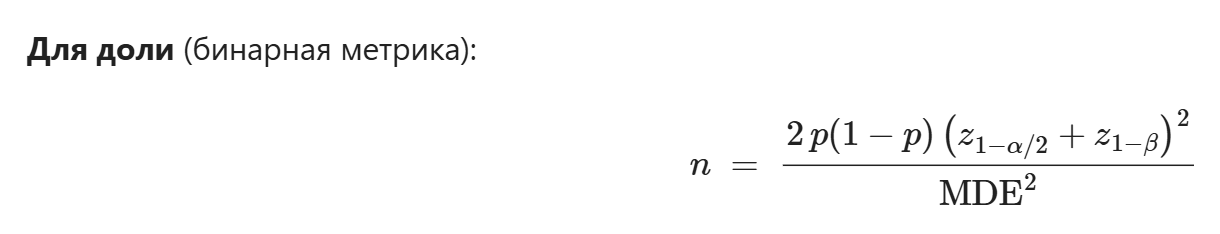
Формула из семинара 5

In [16]:
# your code is here
# Размер выборки на группу для бинарной метрики. Потому что доля - бинарная метрика
def sample_size_proportion(p, mde_rel, alpha=0.01, power=0.8):
    mde_abs = p*mde_rel
    z_alpha = norm.ppf(1 - alpha/2)
    z_beta = norm.ppf(power)
    n = (2*p*(1 - p)*(z_alpha + z_beta)**2)/(mde_abs**2)
    return n

In [17]:
n_target = sample_size_proportion(p0_target, 0.15)
n_guardrail_rent = sample_size_proportion(p0_guardrail_rent, 0.03)
n_guardrail_secondary = sample_size_proportion(p0_guardrail_secondary, 0.03)
n_guardrail_all = sample_size_proportion(p0_guardrail_all, 0.03)

In [67]:
print(f"n на группу (target): {n_target:.0f}")
print(f"n на группу (guardrail rent): {n_guardrail_rent:.0f}")
print(f"n на группу (guardrail secondary): {n_guardrail_secondary:.0f}")
print(f"n на группу (guardrail all): {n_guardrail_all:.0f}")

n на группу (target): 2783659
n на группу (guardrail rent): 572767
n на группу (guardrail secondary): 1761940
n на группу (guardrail all): 426227


In [66]:
max_n_per_group = max(n_target, n_guardrail_rent, n_guardrail_secondary, n_guardrail_all)
total_users_needed = max_n_per_group * 2
print(f"Максимум на группу: {max_n_per_group:.0f}")
print(f"Всего нужно пользователей: {total_users_needed:.0f}")

Максимум на группу: 2783659
Всего нужно пользователей: 5567319


In [83]:
def cumulative_unique_users(df, date_col='timestamp', user_col='user_id'):
    #Накопленное число уникальных пользователей по дням от первого дня
    dates = pd.to_datetime(df[date_col])
    first = dates.groupby(df[user_col]).min()
    day_index = (first - first.min()).dt.days + 1
    return day_index.value_counts().sort_index().cumsum()

In [84]:
# Берем только пользователей, попавших в exposure (main_view)
exposed_df = df_logs[df_logs['event'] == 'main_view'].copy()
exposed_df['date'] = pd.to_datetime(exposed_df['timestamp']).dt.date

In [85]:
cum_users = cumulative_unique_users(exposed_df)
print("Накопление уникальных пользователей по дням:")
print(cum_users.head(20))

Накопление уникальных пользователей по дням:
timestamp
1      317702
2      541200
3      740053
4      916107
5     1069387
6     1208492
7     1338902
8     1443539
9     1516954
10    1583062
11    1641170
12    1691812
13    1738001
14    1781124
Name: count, dtype: int64


In [68]:
# Ищем минимальное число дней, когда накопленное число >= total_users_needed
# (cum_users - это общее число уников, а нам нужно покрыть обе группы, поэтому сравниваем с total_users_needed)
days_needed = (cum_users < total_users_needed).sum() + 1
print(f"Необходимое количество дней (через накопление): {days_needed}")

Необходимое количество дней (через накопление): 15


Минимальное количество дней, за которое в эксперименте наберётся нужное количество уникальных пользователей (в обеих группах вместе), чтобы задетектировать заявленный эффект с заданными альфа= 0.01 и мощностью 80% равно **15**

Но у нас лимит! 14 дней. Мы не успеваем набрать

Отсюда следует необходимость поиска proxy-метрики

#### 3. Рассчитайте MDE для информативных метрик — 2 балла
В реальности эффекты по информативным критериям, которые мы также хотим включать в пресет метрик, нужно сравнивать на достижимость на основе прошлых экспериментов. Как правило, проделав это упражнение один раз, вы просто сохраняете достижимый трешхолд в базе знаний команды и принимаете решение о включении их в базовый набор. Проверка эффектов для каждого теста не требуется. Однако, стоит делать периодический пересмотр зафиксированных достижимых эффектов, например раз в полгода / год, или при сильных изменениях продукта / рынка.

В данном задании мы с вами не будем опираться на историю тестов, просто потренируемся делать обратный расчет — размера эффекта от заданной длительности (14 дней).

*Для числителя используйте только ивенты с источником main_nav*

In [26]:
# your code is here
# Аренда
info_rent_users = df_logs[
    (df_logs['event'] == 'list_view') & 
    (df_logs['source'] == 'main_nav') & 
    (df_logs['category'].isin(['rent_long', 'rent_daily']))
]['user_id'].nunique()
p0_info_rent = info_rent_users/exposed_users
p0_info_rent

0.4150626233771484

In [27]:
# Вторичка
info_secondary_users = df_logs[
    (df_logs['event'] == 'list_view') & 
    (df_logs['source'] == 'main_nav') & 
    (df_logs['category'] == 'secondary')
]['user_id'].nunique()
p0_info_secondary = info_secondary_users/exposed_users
p0_info_secondary

0.22395689463507312

In [34]:
# Новостройки
info_newbuilds_users = df_logs[
    (df_logs['event'] == 'list_view') & 
    (df_logs['source'] == 'main_nav') & 
    (df_logs['category'] == 'newbuilds')
]['user_id'].nunique()
p0_info_newbuilds = info_newbuilds_users/exposed_users
p0_info_newbuilds

0.044574100399522996

In [36]:
# Любая
info_all_nav_users = df_logs[
    (df_logs['event'] == 'list_view') & 
    (df_logs['source'] == 'main_nav')
]['user_id'].nunique()
p0_info_all_nav = info_all_nav_users/exposed_users
p0_info_all_nav

0.545932793000375

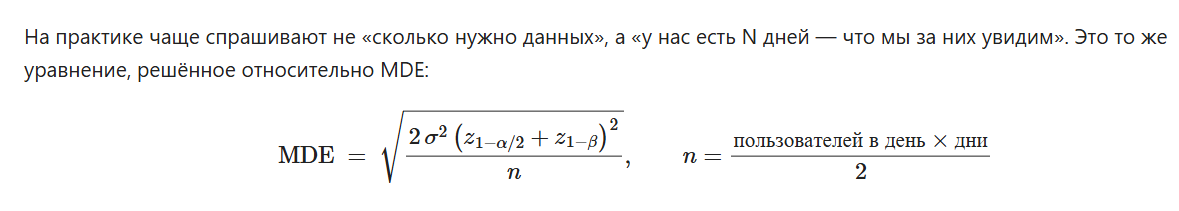
ФОрмула 

In [70]:
# обратная задача
days_planned = 14
if days_planned in cum_users.index:
    users_14_days_total = cum_users[days_planned]
else:
    users_14_days_total = cum_users.iloc[-1]

users_per_group_14_days = users_14_days_total/2
print(f"Пользователей на группу за 14 дней: {users_per_group_14_days:.0f}")

Пользователей на группу за 14 дней: 890562


In [31]:
def mde_proportion(p, n, alpha=0.01, power=0.8):
    #MDE (абсолютный) для бинарной метрики при заданном n
    z_alpha = norm.ppf(1 - alpha/2)
    z_beta = norm.ppf(power)
    return np.sqrt(2*p*(1 - p)*(z_alpha + z_beta) ** 2/n)

In [32]:
# Относительные MDE
mde_info_rent_rel = (mde_proportion(p0_info_rent, users_per_group_14_days)/p0_info_rent) * 100
mde_info_secondary_rel = (mde_proportion(p0_info_secondary, users_per_group_14_days)/p0_info_secondary) * 100
mde_info_newbuilds_rel = (mde_proportion(p0_info_newbuilds, users_per_group_14_days)/p0_info_newbuilds) * 100
mde_info_all_nav_rel = (mde_proportion(p0_info_all_nav, users_per_group_14_days)/p0_info_all_nav) * 100

In [82]:
print("MDE за 14 дней (относительный):")
print(f"Переход в Аренду: {mde_info_rent_rel:.2f}%")
print(f"Переход во Вторичку: {mde_info_secondary_rel:.2f}%")
print(f"Переход в Новостройки: {mde_info_newbuilds_rel:.2f}%")
print(f"Все: {mde_info_all_nav_rel:.2f}%")

MDE за 14 дней (относительный):
Переход в Аренду: 0.61%
Переход во Вторичку: 0.95%
Переход в Новостройки: 2.37%
Все: 0.47%


Информативные метрики в отличие от таргета очень чувствительные. За те же 14 дней мы сможем задетектировать эффекты порядка примерно 0.5-2.5%, а для таргета требовалось 15 дней, и то при большом эффекте плюс 15%

Но информативные не принимают участие в решении, поэтому нужно искать proxy-метрику, которая по итсорическим экспериментам сонаправлена с таргетом

#### 4. Выбираем proxy-метрику (шаг 1) — 2 балла
Стало понятно, что за 14 дней мы не успеем замерить эффект по таргету. Что делать? Можно использовать методы снижения дисперсии, а можно попробовать подобрать proxy-метрику. Давайте реализуем второй вариант.

**Для proxy будем использовать 3-х кандидатов:**
- доля пользователей с просмотром карточки объявления в Новостройках;
- доля пользователей, добавивших в избранное объявление в Новостройках;
- доля пользователей, открывших форму заявки в Новостройках — связь с автором объявления в этом разделе предполагает обратный звонок от офиса продаж, поэтому чтобы сделать событие контакта, релевантное другим разделам, нужно ввести свой номер телефона в форму заявки, расположенную на карточке.

Для каждой из proxy-метрик:
- Рассчитайте MDE для заданной длительности — 14 дней;
- По историческому набору экспериментов постройте диаграмму рассеяния зафиксированных эффектов и длительности тестов (пометьте значимые эффекты).

**Для расчетов метрик используйте следующие ивенты:**
- Для proxy — card_view, add_fav, form_start.

In [38]:
#card_view
proxy_card_users = df_logs[
    (df_logs['event'] == 'card_view') & 
    (df_logs['category'] == 'newbuilds')
]['user_id'].nunique()
p0_proxy_card = proxy_card_users/exposed_users
p0_proxy_card

0.013662720843691962

In [40]:
#add_fav
proxy_fav_users = df_logs[
    (df_logs['event'] == 'add_fav') & 
    (df_logs['category'] == 'newbuilds')
]['user_id'].nunique()
p0_proxy_fav = proxy_fav_users/exposed_users
p0_proxy_fav

0.00395873616884619

In [41]:
#form_start
proxy_form_users = df_logs[
    (df_logs['event'] == 'form_start') & 
    (df_logs['category'] == 'newbuilds')
]['user_id'].nunique()
p0_proxy_form = proxy_form_users/exposed_users
p0_proxy_form 

0.0007186473260705038

In [86]:
# MDE за 14 дней (та же обратная формула, что и для информативных метрик)
mde_proxy_card_rel = (mde_proportion(p0_proxy_card, users_per_group_14_days)/p0_proxy_card) * 100
mde_proxy_fav_rel = (mde_proportion(p0_proxy_fav, users_per_group_14_days)/p0_proxy_fav) * 100
mde_proxy_form_rel = (mde_proportion(p0_proxy_form, users_per_group_14_days)/p0_proxy_form) * 100

print("MDE за 14 дней для proxy-метрик (относительный):")
print(f"Просмотр карточки: {mde_proxy_card_rel:.2f}%")
print(f"Добавление в избранное: {mde_proxy_fav_rel:.2f}%")
print(f"Открытие формы: {mde_proxy_form_rel:.2f}%")

MDE за 14 дней для proxy-метрик (относительный):
Просмотр карточки: 4.35%
Добавление в избранное: 8.12%
Открытие формы: 19.10%


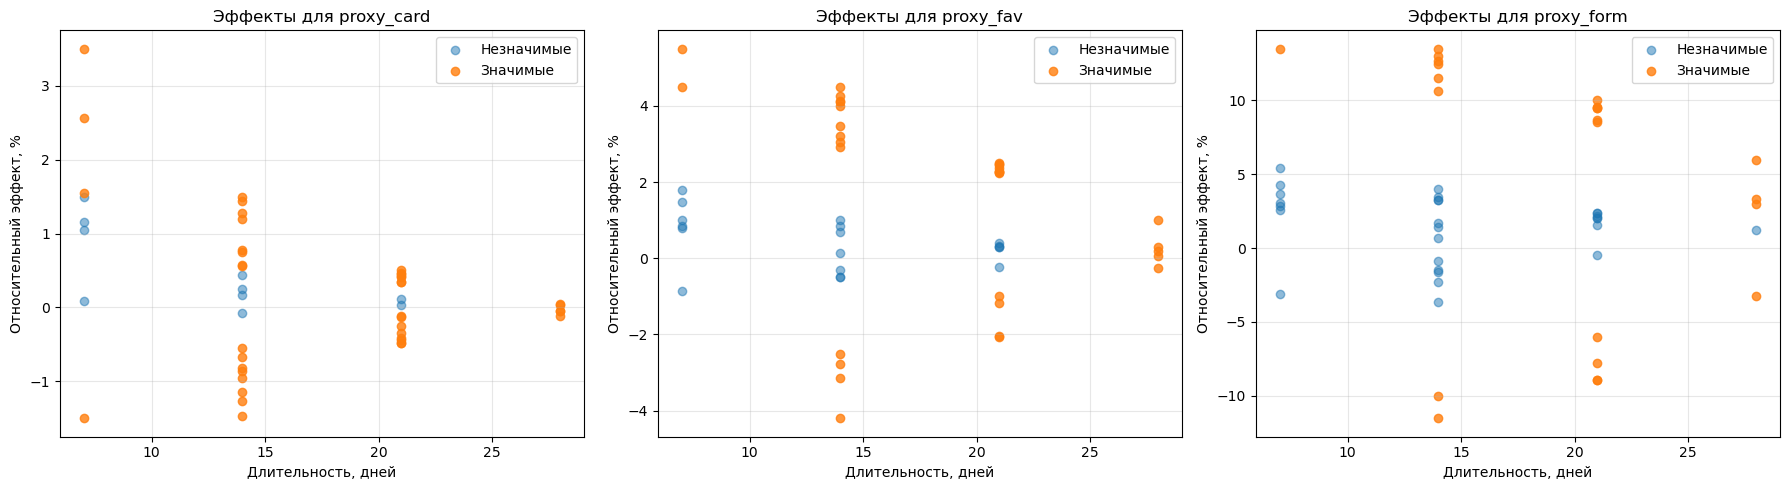

In [88]:
# Диаграммы рассеяния
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

def proxy_scatter(ax, df, proxy_name):
    significant = df[f'{proxy_name}_p_value'] < 0.01
    non_significant = df[f'{proxy_name}_p_value'] >= 0.01
    
    ax.scatter(df.loc[non_significant, 'days'], 
               df.loc[non_significant, f'{proxy_name}_effect_rel'] * 100, 
               alpha=0.5, label='Незначимые')
    ax.scatter(df.loc[significant, 'days'], 
               df.loc[significant, f'{proxy_name}_effect_rel'] * 100, 
               alpha=0.8, label='Значимые')
    
    ax.set_title(f'Эффекты для {proxy_name}')
    ax.set_xlabel('Длительность, дней')
    ax.set_ylabel('Относительный эффект, %')
    ax.legend()
    ax.grid(alpha=0.3)

proxy_scatter(axes[0], df_exps, 'proxy_card')
proxy_scatter(axes[1], df_exps, 'proxy_fav')
proxy_scatter(axes[2], df_exps, 'proxy_form')

plt.tight_layout()
plt.show()

proxy_card - самая чувствительная, значимые эффекты появляются уже при +-1-3%

proxy_fav - средняя, значимые эффекты при +-3-5%.

proxy_form - самая нечувствительная, значимые эффекты только при +-10-15%.

Чем выше событие в воронке, тем выше база, тем ниже MDE - метрика чувствительнее, но ее связь с таргетом слабее
Чем ниже событие в воронке, тем ниже база, тем выше MDE - метрика менее чувствительна, но ближе к таргету по смыслу.

#### 5. Выбираем proxy-метрику (шаг 2) — 2 балла
Для каждой из proxy-метрик по историческому набору экспериментов рассчитайте:
- Binary Sensitivity;
- MSE с таргет-метрикой;
- Корреляцию Пирсона с таргет-метрикой.

In [76]:
# your code is here
target_effect = df_exps['target_contact_effect_rel']
target_p_value = df_exps['target_contact_p_value']
target_significant = target_p_value < 0.01

In [77]:
proxy_names = ['proxy_card', 'proxy_fav', 'proxy_form']
results = []

In [78]:
for proxy in proxy_names:
    proxy_effect = df_exps[f'{proxy}_effect_rel']
    proxy_p_value = df_exps[f'{proxy}_p_value']
    proxy_significant = proxy_p_value < 0.01
    
    binary_sensitivity = proxy_significant.mean()
    mse = np.mean((proxy_effect - target_effect) ** 2)
    correlation, k = pearsonr(proxy_effect, target_effect)
    
    results.append({
        'proxy_metric': proxy,
        'binary_sensitivity': binary_sensitivity,
        'mse': mse,
        'pearson_correlation': correlation,
    })

In [79]:
df_results = pd.DataFrame(results).set_index('proxy_metric')

In [80]:
print(df_results)
print(f"Binary Sensitivity таргет-метрики: {target_significant.mean():.3f}")

              binary_sensitivity       mse  pearson_correlation
proxy_metric                                                   
proxy_card                  0.80  0.014300             0.150005
proxy_fav                   0.64  0.011042             0.669678
proxy_form                  0.46  0.006551             0.723834
Binary Sensitivity таргет-метрики: 0.400


С точки зрения binary_sensitivity выигрывает proxy_card, но по mse лучше proxy_form, а по pearson_correlation ближе к таргету proxy_fav и proxy_form

Пока что proxy_fav выглядит наиболее сбалансированным по чувствительности и сонаправленности

#### 6. Выбираем proxy-метрику (шаг 3) — 2 балла
Для каждой из proxy-метрик по историческому набору экспериментов:
- Рассчитайте Proxy Score;
- Выведите матрицу согласия-несогласия знаков с таргет-метрикой.

Выберите proxy, с которой вы пойдете в а/б тест, обоснуйте выбор.

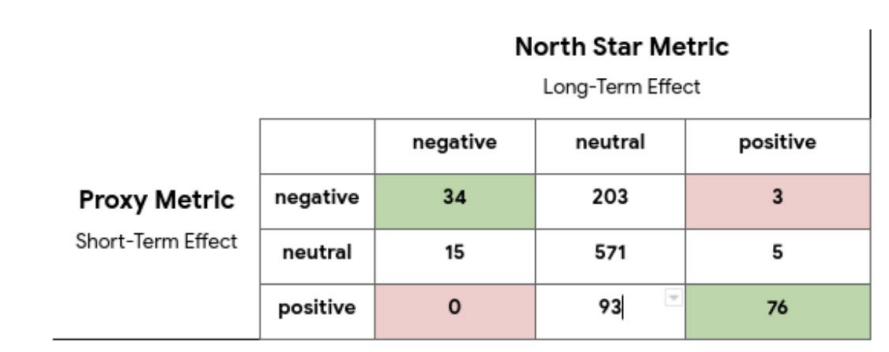

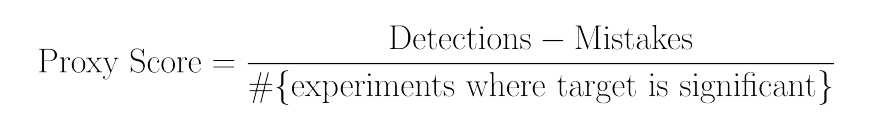

In [53]:
# your code is here
proxy_scores = []
for proxy in proxy_names:
    proxy_effect = df_exps[f'{proxy}_effect_rel']
    proxy_p_value = df_exps[f'{proxy}_p_value']
    proxy_significant = proxy_p_value < 0.01
    
    detections = (
        (proxy_significant) & (target_significant) & 
        (np.sign(proxy_effect) == np.sign(target_effect))
    ).sum()
    
    mistakes = (
        (proxy_significant) & (target_significant) & 
        (np.sign(proxy_effect) != np.sign(target_effect))
    ).sum()
    
    n_target_significant = target_significant.sum()
    proxy_score = (detections - mistakes)/n_target_significant if n_target_significant > 0 else np.nan
    proxy_scores.append({'proxy_metric': proxy, 'proxy_score': proxy_score})

In [54]:
df_proxy_scores = pd.DataFrame(proxy_scores).set_index('proxy_metric')

In [55]:
print("Proxy Score:")
print(df_proxy_scores)

Proxy Score:
              proxy_score
proxy_metric             
proxy_card           0.20
proxy_fav            0.85
proxy_form           0.60


proxy_fav            0.85!!

In [90]:
# Матрица согласия-несогласия
for proxy in proxy_names:
    # Знак: -1 0 +1, где 0 = незначимо
    p_sign = np.where(df_exps[f'{proxy}_p_value'] < 0.01,
                      np.sign(df_exps[f'{proxy}_effect_rel']), 0)
    t_sign = np.where(target_p_value < 0.01, np.sign(target_effect), 0)
    
    labels = {-1: 'negative', 0: 'neutral', 1: 'positive'}
    p_labels = [labels[x] for x in p_sign]
    t_labels = [labels[x] for x in t_sign]
    
    # Кросс-таблица
    matrix = pd.crosstab(
        pd.Series(t_labels, name='Target'),
        pd.Series(p_labels, name='Proxy'),
    ).reindex(index=['negative', 'neutral', 'positive'],
              columns=['negative', 'neutral', 'positive'],
              fill_value=0)
    
    print(f"\n{proxy}:")
    print(matrix)


proxy_card:
Proxy     negative  neutral  positive
Target                               
negative         2        0         0
neutral         11        8        11
positive         7        2         9

proxy_fav:
Proxy     negative  neutral  positive
Target                               
negative         2        0         0
neutral          7       15         8
positive         0        3        15

proxy_form:
Proxy     negative  neutral  positive
Target                               
negative         1        1         0
neutral          6       19         5
positive         0        7        11


proxy_fav - обратить внимание

Итог: proxy_fav - оптимальный вариант для чувствительности, сонаправленности и бизнес-смысла. 
С этой метрикой мы идем в A/B-тест. Если эта метрика покажет значимый эффект, это будет хорошим сигналом, что и таргет (заявки в Новостройках) тоже сдвинулся в ту же сторону